## Lab 6 Solution – Frequency Domain Filtering

# Step 1: Import Libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Step 2: Load & Resize Image

In [3]:
image = data.camera()                # load cameraman
image = resize(image, (256, 256))    # resize for speed
M, N = image.shape                   # get size

# Step 3: Define Sobel Kernels

In [5]:
sobel_x = np.array([[-1, 0, 1],   # Detects horizontal edges
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1], # Detects vertical edges
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Step 4: Center Kernel + FFT Function

In [6]:
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)          # zero array
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2         # center coords

    # place kernel at center
    padded[cy - kh//2 : cy - kh//2 + kh,
           cx - kw//2 : cx - kw//2 + kw] = kernel

    # shift then FFT
    return np.fft.fft2(np.fft.ifftshift(padded))

# Step 5: FFT of Image

In [7]:
F = np.fft.fft2(image)

# Step 6: FFT of Sobel Filters

In [8]:
H_sobel_x = center_embed_kernel(sobel_x, image.shape)
H_sobel_y = center_embed_kernel(sobel_y, image.shape)

# Step 7: Apply Filters 

In [9]:
F_sobel_x = F * H_sobel_x
F_sobel_y = F * H_sobel_y

# Step 8: Inverse FFT

In [10]:
sobel_x_image = np.fft.ifft2(F_sobel_x).real
sobel_y_image = np.fft.ifft2(F_sobel_y).real

# gradient magnitude
sobel_magnitude = np.sqrt(sobel_x_image**2 + sobel_y_image**2)

# Step 9: Plot Results

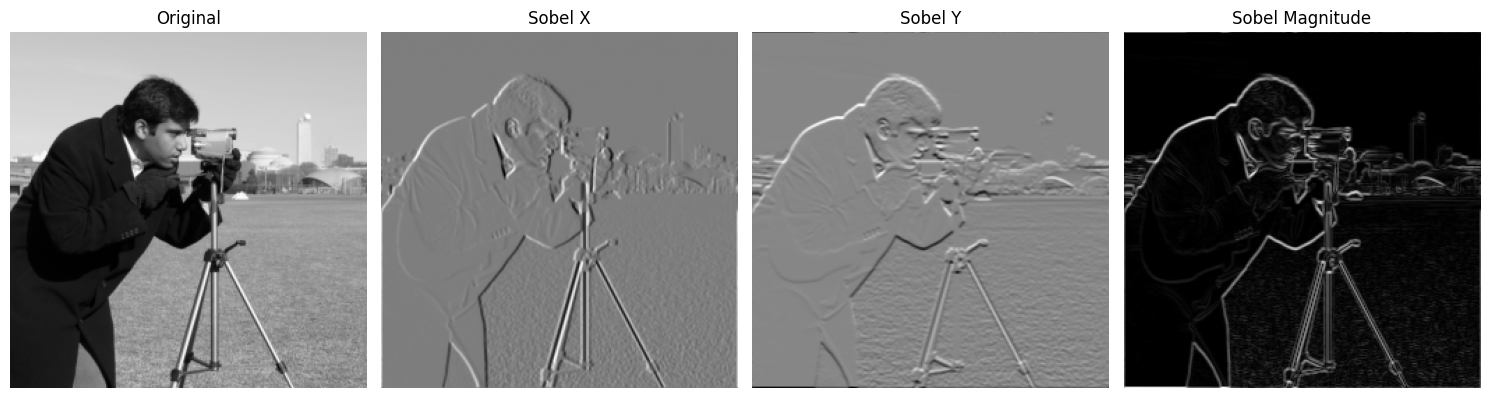

In [11]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(sobel_x_image, cmap='gray')
plt.title('Sobel X')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(sobel_y_image, cmap='gray')
plt.title('Sobel Y')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel Magnitude')
plt.axis('off')

plt.tight_layout()
plt.show()

# Frequency Spectrums (Optional)

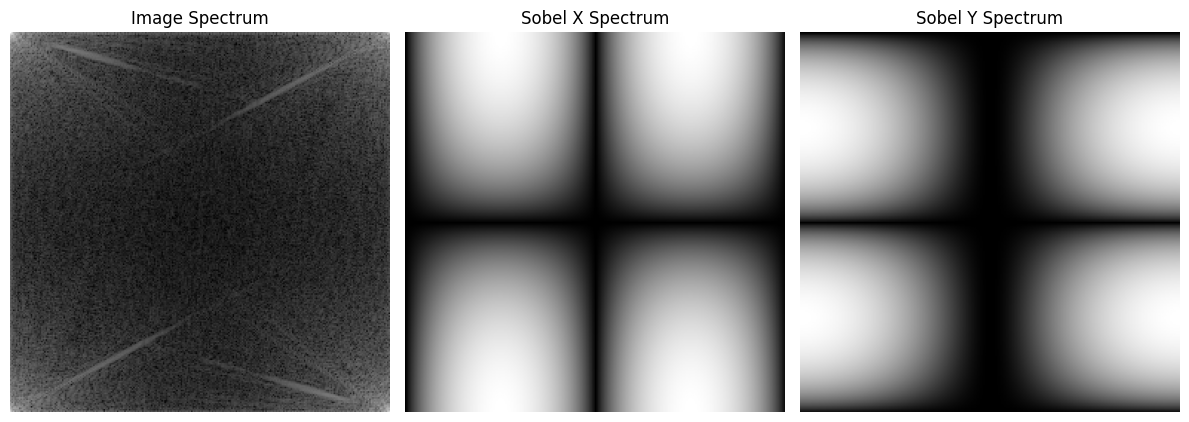

In [12]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(np.log(1 + np.abs(F)), cmap='gray')
plt.title('Image Spectrum')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(H_sobel_x)), cmap='gray')
plt.title('Sobel X Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(np.log(1 + np.abs(H_sobel_y)), cmap='gray')
plt.title('Sobel Y Spectrum')
plt.axis('off')

plt.tight_layout()
plt.show()